In [40]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("prosperchuks/health-dataset")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\G2N\.cache\kagglehub\datasets\prosperchuks\health-dataset\versions\5


In [41]:
import pandas as pd
import os

# Load the dataset
df = pd.read_csv(os.path.join(path, "diabetes_data.csv"))

df.head()

#shape
print("Shape of the dataset:", df.shape)
#null values
print("Null values in the dataset:\n", df.isnull().sum())
print("\nTarget distribution (0 = Healthy, 1 = Diabetes):\n", df['Diabetes'].value_counts())

Shape of the dataset: (70692, 18)
Null values in the dataset:
 Age                     0
Sex                     0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Stroke                  0
HighBP                  0
Diabetes                0
dtype: int64

Target distribution (0 = Healthy, 1 = Diabetes):
 Diabetes
0.0    35346
1.0    35346
Name: count, dtype: int64


In [42]:
from sklearn.model_selection import train_test_split

# Split the dataset into features and target variable
x = df.drop('Diabetes', axis=1)
y = df['Diabetes']

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print(f"Training patients: {X_train.shape[0]}")
print(f"Testing patients:  {X_test.shape[0]}")

Training patients: 56553
Testing patients:  14139


In [43]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train['BMI'] = scaler.fit_transform(X_train[['BMI']])
X_test['BMI'] = scaler.transform(X_test[['BMI']])

# If you already ran your snippet, drop the lowercase duplicate:
X_train = X_train.drop(columns=['bmi'], errors='ignore')
X_test = X_test.drop(columns=['bmi'], errors='ignore')

print("BMI standardized. Mean of training BMI:", X_train['BMI'].mean())
print("BMI standardized. Standard deviation of training BMI:", X_train['BMI'].std())

BMI standardized. Mean of training BMI: -1.5479084229951435e-16
BMI standardized. Standard deviation of training BMI: 1.0000088413812007


In [44]:
df.head()

,Age,Sex,HighChol,CholCheck,BMI,Smoker,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,GenHlth,MentHlth,PhysHlth,DiffWalk,Stroke,HighBP,Diabetes
0,4.0,1.0,0.0,1.0,26.0,0.0,0.0,1.0,0.0,1.0,0.0,3.0,5.0,30.0,0.0,0.0,1.0,0.0
1,12.0,1.0,1.0,1.0,26.0,1.0,0.0,0.0,1.0,0.0,0.0,3.0,0.0,0.0,0.0,1.0,1.0,0.0
2,13.0,1.0,0.0,1.0,26.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,10.0,0.0,0.0,0.0,0.0
3,11.0,1.0,1.0,1.0,28.0,1.0,0.0,1.0,1.0,1.0,0.0,3.0,0.0,3.0,0.0,0.0,1.0,0.0
4,8.0,0.0,0.0,1.0,29.0,1.0,0.0,1.0,1.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0


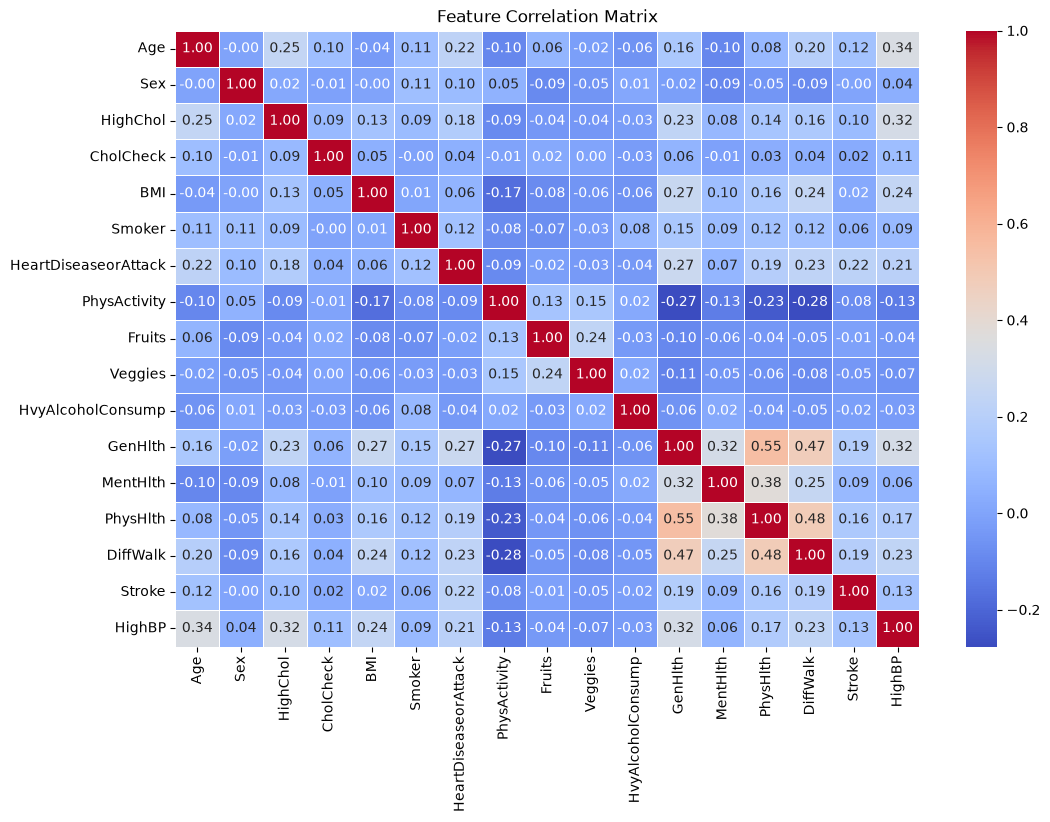

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the correlation matrix
# numeric_only=True prevents errors if your dataset has string/categorical columns
corr_matrix = X_train.corr(numeric_only=True)

# Set up the figure size
plt.figure(figsize=(12, 8))

# Draw the heatmap
sns.heatmap(
    corr_matrix, 
    annot=True,          # Shows the correlation numbers inside the squares
    cmap='coolwarm',     # Color palette (red for positive, blue for negative)
    fmt=".2f",           # Rounds the numbers to 2 decimal places
    linewidths=0.5       # Adds a small border between squares for readability
)

# Add a title and display the plot
plt.title("Feature Correlation Matrix")
plt.show()

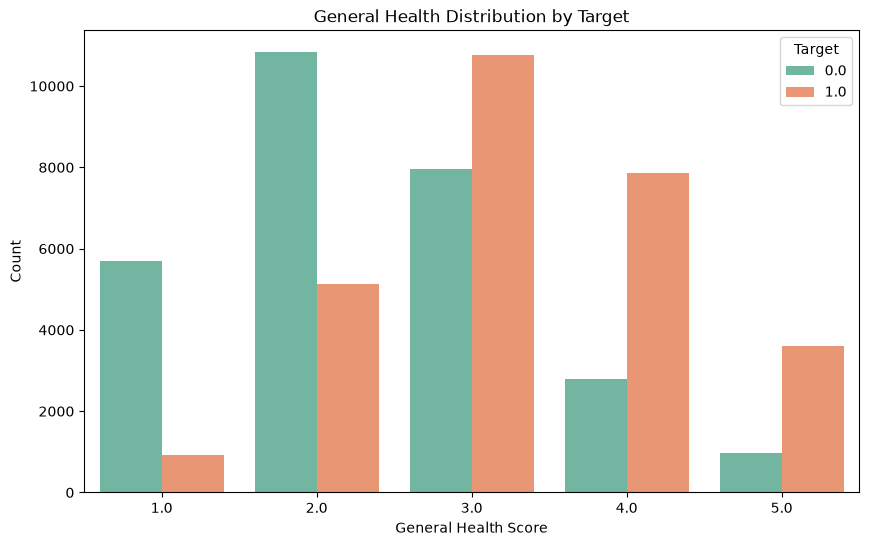

In [46]:
plt.figure(figsize=(10, 6))
# Countplot grouped by the feature, colored by the target
train_data = X_train.copy()
train_data['target'] = y_train.values  # Add the target variable to the training data
sns.countplot(data=train_data, x='GenHlth', hue='target', palette='Set2')
plt.title("General Health Distribution by Target")
plt.xlabel("General Health Score")
plt.ylabel("Count")
plt.legend(title='Target')
plt.show()

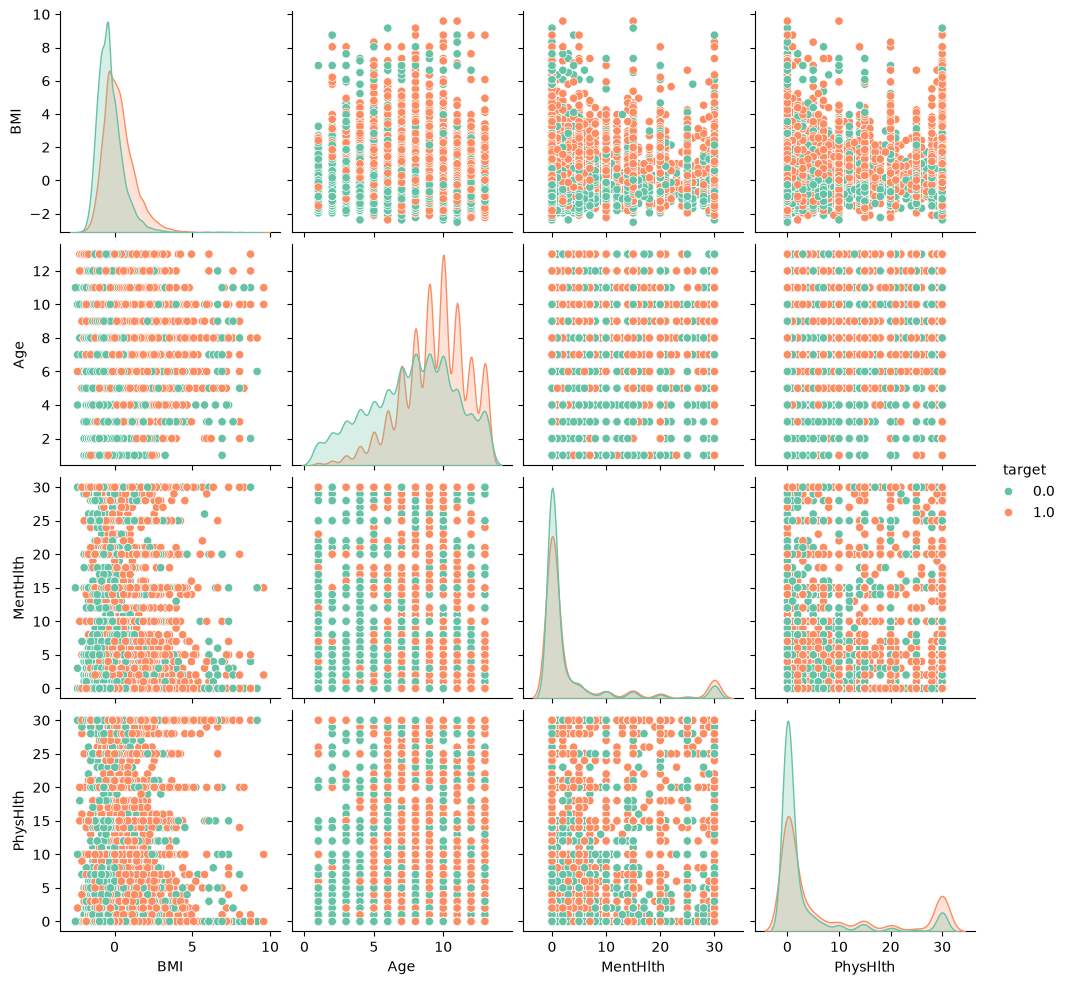

In [48]:
features_to_plot = ['BMI', 'Age', 'MentHlth', 'PhysHlth','target'] 

# Create the pairplot, color-coded by the target
sns.pairplot(train_data[features_to_plot], hue='target', palette='Set2', diag_kind='kde')
plt.show()

In [49]:
# 1. Calculate absolute correlation using ONLY training data
corr = X_train.corrwith(y_train).abs()

# 2. Keep features with |corr| > 0.10
selected_cols = corr[corr > 0.10].index

# 3. Filter both sets (and re-run your StandardScaler after this!)
X_train = X_train[selected_cols]
X_test = X_test[selected_cols]

In [50]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Initialize the model (n_jobs=-1 uses all your CPU cores)
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)

# 2. Train on the scaled training data
rf_model.fit(X_train, y_train)

# 3. Predict on the test data
y_pred = rf_model.predict(X_test)

# 4. Evaluate performance
print(classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.77      0.71      0.74      7090
         1.0       0.73      0.79      0.76      7049

    accuracy                           0.75     14139
   macro avg       0.75      0.75      0.75     14139
weighted avg       0.75      0.75      0.75     14139

Confusion Matrix:
 [[5013 2077]
 [1471 5578]]


In [51]:
print("Train Acc:", rf_model.score(X_train, y_train))
print("Test Acc: ", rf_model.score(X_test, y_test))

Train Acc: 0.7667497745477694
Test Acc:  0.7490628757337859


In [52]:
pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

GenHlth                 0.254108
HighBP                  0.251986
BMI                     0.156631
Age                     0.108977
HighChol                0.087954
DiffWalk                0.054203
PhysHlth                0.033810
HeartDiseaseorAttack    0.026408
CholCheck               0.010134
PhysActivity            0.008810
Stroke                  0.006978
dtype: float64

In [53]:
# Keep only features with >= 2% importance
top_cols = ['GenHlth', 'HighBP', 'BMI', 'Age', 'HighChol', 'DiffWalk', 'PhysHlth', 'HeartDiseaseorAttack']

rf_slim = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_slim.fit(X_train[top_cols], y_train)

print("All 11 cols Test Acc:", rf_model.score(X_test, y_test))
print("Top 8 cols Test Acc: ", rf_slim.score(X_test[top_cols], y_test))

All 11 cols Test Acc: 0.7490628757337859
Top 8 cols Test Acc:  0.7460923686257869


In [54]:
from sklearn.model_selection import RandomizedSearchCV

# 1. Define the hyperparameter grid to explore
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [8, 10, 12, 15, None],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 4, 8],
    'max_features': ['sqrt', 'log2']
}

# 2. Set up RandomizedSearch (n_iter=10 tests 10 random combos, cv=3 does 3-fold cross-validation)
random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='f1', # or 'accuracy' / 'recall'
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# 3. Run the search on your training set
random_search.fit(X_train, y_train)

# 4. Grab the winning settings and test them
print("Best Parameters:", random_search.best_params_)
best_rf = random_search.best_estimator_
print("Tuned Test Acc:", best_rf.score(X_test, y_test))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 8}
Tuned Test Acc: 0.747719074899215


In [55]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,          # Boosted trees prefer shallow depths (4 to 6)
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGB Train Acc:", xgb_model.score(X_train, y_train))
print("XGB Test Acc: ", xgb_model.score(X_test, y_test))
print(classification_report(y_test, xgb_model.predict(X_test)))

XGB Train Acc: 0.7572896221243789
XGB Test Acc:  0.7509724874460711
              precision    recall  f1-score   support

         0.0       0.78      0.71      0.74      7090
         1.0       0.73      0.80      0.76      7049

    accuracy                           0.75     14139
   macro avg       0.75      0.75      0.75     14139
weighted avg       0.75      0.75      0.75     14139



In [57]:
for data in [X_train, X_test]:
    # 1. Total Cardiovascular Risk Count (0 to 4 conditions)
    data['Cardio_Risk_Score'] = (
        data['HighBP'] + data['HighChol'] + data['HeartDiseaseorAttack'] + data['Stroke']
    )
    
    # 2. Interaction terms (BMI + Age, and General + Physical Health)
    data['BMI_x_Age'] = data['BMI'] * data['Age']
    data['Health_Burden'] = data['GenHlth'] * (data['PhysHlth'] + 1)
    
print("New features added. Sample of training data:\n", X_train.head())

New features added. Sample of training data:
         Age  HighChol  CholCheck       BMI  HeartDiseaseorAttack  \
61789  11.0       0.0        1.0 -0.687371                   0.0   
46280  11.0       1.0        1.0 -0.405776                   1.0   
18465   8.0       0.0        1.0 -0.405776                   0.0   
45540  12.0       1.0        1.0 -0.687371                   0.0   
28119   5.0       1.0        1.0 -0.546574                   0.0   

       PhysActivity  GenHlth  PhysHlth  DiffWalk  Stroke  HighBP  \
61789           1.0      4.0       3.0       0.0     0.0     1.0   
46280           0.0      5.0      30.0       1.0     0.0     1.0   
18465           1.0      4.0      27.0       1.0     0.0     1.0   
45540           1.0      3.0       0.0       0.0     0.0     0.0   
28119           1.0      3.0       2.0       1.0     0.0     1.0   

       Cardio_Risk_Score  BMI_x_Age  Health_Burden  
61789                1.0  -7.561083           16.0  
46280                3.0  -4.4

In [58]:
xgb_model.fit(X_train, y_train)

print("XGB Train Acc:", xgb_model.score(X_train, y_train))
print("XGB Test Acc: ", xgb_model.score(X_test, y_test))
print(classification_report(y_test, xgb_model.predict(X_test)))

XGB Train Acc: 0.7590225098580093
XGB Test Acc:  0.7516797510432138
              precision    recall  f1-score   support

         0.0       0.78      0.71      0.74      7090
         1.0       0.73      0.80      0.76      7049

    accuracy                           0.75     14139
   macro avg       0.75      0.75      0.75     14139
weighted avg       0.75      0.75      0.75     14139



In [60]:
pd.Series(xgb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

HighBP                  0.403037
Cardio_Risk_Score       0.217803
GenHlth                 0.159746
Age                     0.041904
CholCheck               0.029270
BMI_x_Age               0.027246
Health_Burden           0.026392
BMI                     0.022285
DiffWalk                0.021506
HighChol                0.017275
HeartDiseaseorAttack    0.012632
PhysHlth                0.007611
Stroke                  0.007161
PhysActivity            0.006132
dtype: float32

In [61]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# 1. Get the predicted probabilities for class 1 (Diabetes)
y_probs = xgb_model.predict_proba(X_test)[:, 1]

# 2. Apply the 0.45 threshold instead of the default 0.50
y_pred_tuned = (y_probs >= 0.45).astype(int)

# 3. Evaluate the tuned predictions
print("Classification Report (Threshold = 0.45):")
print(classification_report(y_test, y_pred_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Classification Report (Threshold = 0.45):
              precision    recall  f1-score   support

         0.0       0.81      0.66      0.72      7090
         1.0       0.71      0.84      0.77      7049

    accuracy                           0.75     14139
   macro avg       0.76      0.75      0.75     14139
weighted avg       0.76      0.75      0.75     14139


Confusion Matrix:
[[4662 2428]
 [1123 5926]]
